In [1]:
# Summarize the ichorCNA metrics across RA cases (≥2 samples)
import math
import re
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from openpyxl import load_workbook


# ==============================================================
# Input and output paths
# ==============================================================

BASE_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/APOLLO/"
    "APOLLO_Broad/RA_Cases"
)

INPUT_XLSX = BASE_DIR / "APOLLO_RA_cfDNA_metrics.xlsx"

# Figures will be saved directly in RA_Cases.
OUTPUT_DIR = BASE_DIR
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ==============================================================
# Metrics to plot
# ==============================================================

METRICS = [
    (
        "Tumor_fraction",
        "Tumor fraction",
        "RA_ERpos_longitudinal_Tumor_fraction.png",
    ),
    (
        "Ploidy",
        "Ploidy",
        "RA_ERpos_longitudinal_Ploidy.png",
    ),
    (
        "Subclol_fraction",
        "Subclonal fraction",
        "RA_ERpos_longitudinal_Subclol_fraction.png",
    ),
    (
        "Frac_Genome_Subclol",
        "Fraction genome subclonal",
        "RA_ERpos_longitudinal_Frac_Genome_Subclol.png",
    ),
    (
        "Frac_C_Subclol",
        "Fraction CNA subclonal",
        "RA_ERpos_longitudinal_Frac_C_Subclol.png",
    ),
]


# Histology colours
HISTOLOGY_COLORS = {
    "IDC": "#2C5F8A",
    "ILC": "#D97706",
    "Mixed": "#2E8B57",
}


# ==============================================================
# Helper functions
# ==============================================================

def rapid_case_number(case_name):
    """Return numeric part of RA# for proper case ordering."""
    match = re.search(r"\d+", str(case_name))
    return int(match.group()) if match else 10**9


def histology_group(value):
    """Combine IDC/ILC and ILC/IDC into Mixed."""
    value = str(value or "").strip().upper()

    if value == "IDC":
        return "IDC"

    if value == "ILC":
        return "ILC"

    if value in {"IDC/ILC", "ILC/IDC"}:
        return "Mixed"

    return "Mixed"


def is_er_positive(value):
    """Identify positive and weak-positive ER cases."""
    return str(value or "").strip().lower() in {
        "positive",
        "weak positive",
        "pos",
        "weak pos",
    }


def valid_number(value):
    """Convert valid numerical values; retain missing values as NaN."""
    if value is None or str(value).strip() == "":
        return float("nan")

    try:
        value = float(value)

        if math.isnan(value):
            return float("nan")

        return value

    except (TypeError, ValueError):
        return float("nan")


# ==============================================================
# Read RA workbook
# ==============================================================

if not INPUT_XLSX.is_file():
    raise FileNotFoundError(f"Workbook not found:\n{INPUT_XLSX}")

workbook = load_workbook(
    INPUT_XLSX,
    data_only=True,
    read_only=True,
)

if "RA cfDNA Metrics" not in workbook.sheetnames:
    raise ValueError(
        "Sheet 'RA cfDNA Metrics' was not found.\n"
        f"Available sheets: {workbook.sheetnames}"
    )

worksheet = workbook["RA cfDNA Metrics"]

headers = [cell.value for cell in worksheet[1]]
column_index = {
    header: index
    for index, header in enumerate(headers)
    if header is not None
}

required_columns = [
    "Rapid Cases",
    "Histology  IDC/ILC",
    "Sample ID (TP number)",
    "ER Status",
    "Tumor_fraction",
    "Ploidy",
    "Subclol_fraction",
    "Frac_Genome_Subclol",
    "Frac_C_Subclol",
]

missing_columns = [
    column
    for column in required_columns
    if column not in column_index
]

if missing_columns:
    raise ValueError(
        "Required columns are missing:\n"
        + "\n".join(missing_columns)
    )


# ==============================================================
# Reconstruct cases from merged Rapid Cases cells
# ==============================================================

all_cases = defaultdict(list)
current_case = None

for values in worksheet.iter_rows(min_row=2, values_only=True):

    rapid_case_value = values[column_index["Rapid Cases"]]

    # Only the first cell of a merged range contains the RA number.
    if rapid_case_value not in (None, ""):
        current_case = str(rapid_case_value).strip()

    if current_case is None:
        continue

    row = {
        header: values[index]
        for header, index in column_index.items()
    }

    row["Rapid Cases"] = current_case
    all_cases[current_case].append(row)


# ==============================================================
# Select ER+ cases with at least two samples
# ==============================================================

longitudinal_cases = {
    case: rows
    for case, rows in all_cases.items()
    if (
        len(rows) >= 2
        and is_er_positive(rows[0]["ER Status"])
    )
}

ordered_cases = sorted(
    longitudinal_cases,
    key=rapid_case_number,
)

number_of_cases = len(ordered_cases)
number_of_samples = sum(
    len(longitudinal_cases[case])
    for case in ordered_cases
)

print(f"ER+ longitudinal cases: {number_of_cases}")
print(f"Samples included: {number_of_samples}")

if number_of_cases != 45 or number_of_samples != 205:
    print(
        "\nWarning: the current workbook does not contain the expected "
        "45 cases and 205 samples."
    )


# ==============================================================
# Plot settings
# ==============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "semibold",
    "axes.edgecolor": "#B8C2CC",
    "axes.linewidth": 0.7,
})

# Dynamically select the grid based on the number of cases.
number_of_columns = 5
number_of_rows = math.ceil(number_of_cases / number_of_columns)


# ==============================================================
# Create one figure for each metric
# ==============================================================

saved_figures = []

for metric, display_name, output_filename in METRICS:

    figure, axes = plt.subplots(
        number_of_rows,
        number_of_columns,
        figsize=(18, number_of_rows * 2.4),
        sharey=True,
        squeeze=False,
    )

    axes = axes.ravel()

    # Collect valid values to determine the y-axis range.
    all_metric_values = []

    for case in ordered_cases:
        for row in longitudinal_cases[case]:
            value = valid_number(row.get(metric))

            if not math.isnan(value):
                all_metric_values.append(value)

    # Fractions use a common 0–1 scale.
    if metric in {
        "Tumor_fraction",
        "Subclol_fraction",
        "Frac_Genome_Subclol",
        "Frac_C_Subclol",
    }:
        y_min = 0
        y_max = max(1.0, max(all_metric_values, default=1.0))

    # Ploidy uses its observed range.
    else:
        observed_min = min(all_metric_values)
        observed_max = max(all_metric_values)
        padding = max(
            0.1,
            (observed_max - observed_min) * 0.08,
        )

        y_min = max(0, observed_min - padding)
        y_max = observed_max + padding

    # ----------------------------------------------------------
    # Plot each patient separately
    # ----------------------------------------------------------

    for axis, case in zip(axes, ordered_cases):

        case_rows = longitudinal_cases[case]

        histology = histology_group(
            case_rows[0]["Histology  IDC/ILC"]
        )

        colour = HISTOLOGY_COLORS[histology]

        sample_order = list(
            range(1, len(case_rows) + 1)
        )

        metric_values = [
            valid_number(row.get(metric))
            for row in case_rows
        ]

        axis.plot(
            sample_order,
            metric_values,
            color=colour,
            linewidth=1.7,
            marker="o",
            markersize=4,
            markerfacecolor="white",
            markeredgewidth=1.2,
        )

        axis.set_title(
            f"{case} | {histology}",
            fontsize=8.5,
            loc="left",
            pad=3,
            color="#263238",
        )

        axis.set_xlim(
            0.7,
            max(sample_order) + 0.3,
        )

        axis.set_ylim(y_min, y_max)
        axis.set_xticks(sample_order)

        axis.tick_params(
            axis="both",
            labelsize=7,
            length=2.5,
            colors="#4B5563",
        )

        axis.grid(
            axis="y",
            color="#E6EBF0",
            linewidth=0.6,
        )

        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)

        if all(math.isnan(value) for value in metric_values):
            axis.text(
                0.5,
                0.5,
                "No evaluable values",
                transform=axis.transAxes,
                horizontalalignment="center",
                verticalalignment="center",
                fontsize=7,
                color="#7A7A7A",
            )

    # Remove unused grid panels if the number of cases changes.
    for axis in axes[number_of_cases:]:
        axis.set_visible(False)

    # ----------------------------------------------------------
    # Legend
    # ----------------------------------------------------------

    legend_handles = [
        Line2D(
            [0],
            [0],
            color=colour,
            marker="o",
            markersize=5,
            markerfacecolor="white",
            linewidth=1.8,
            label=label,
        )
        for label, colour in HISTOLOGY_COLORS.items()
    ]

    figure.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.968),
        ncol=3,
        frameon=False,
        fontsize=10,
    )

    # ----------------------------------------------------------
    # Figure labels
    # ----------------------------------------------------------

    figure.suptitle(
        f"{display_name} trajectories across "
        f"{number_of_cases} ER+ longitudinal rapid-autopsy cases",
        fontsize=16,
        fontweight="bold",
        y=0.992,
        color="#17365D",
    )

    figure.text(
        0.5,
        0.976,
        f"Each panel is one patient; x-axis is ordered sample number "
        f"({number_of_samples} samples total)",
        horizontalalignment="center",
        verticalalignment="top",
        fontsize=10,
        color="#4B5563",
    )

    figure.supxlabel(
        "Sample order within patient",
        fontsize=11,
        y=0.012,
    )

    figure.supylabel(
        display_name,
        fontsize=11,
        x=0.012,
    )

    figure.tight_layout(
        rect=(0.025, 0.028, 0.995, 0.952),
        h_pad=1.3,
        w_pad=1.0,
    )

    # ----------------------------------------------------------
    # Save high-resolution PNG
    # ----------------------------------------------------------

    output_path = OUTPUT_DIR / output_filename

    figure.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.close(figure)
    saved_figures.append(output_path)


# ==============================================================
# Completion summary
# ==============================================================

print("\nPlots saved successfully:")

for figure_path in saved_figures:
    print(figure_path)

ER+ longitudinal cases: 45
Samples included: 205

Plots saved successfully:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/APOLLO/APOLLO_Broad/RA_Cases/RA_ERpos_longitudinal_Tumor_fraction.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/APOLLO/APOLLO_Broad/RA_Cases/RA_ERpos_longitudinal_Ploidy.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/APOLLO/APOLLO_Broad/RA_Cases/RA_ERpos_longitudinal_Subclol_fraction.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/APOLLO/APOLLO_Broad/RA_Cases/RA_ERpos_longitudinal_Frac_Genome_Subclol.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/APOLLO/APOLLO_Broad/RA_Cases/RA_ERpos_longitudinal_Frac_C_Subclol.png


ER+ longitudinal cases: 45
Total samples: 205


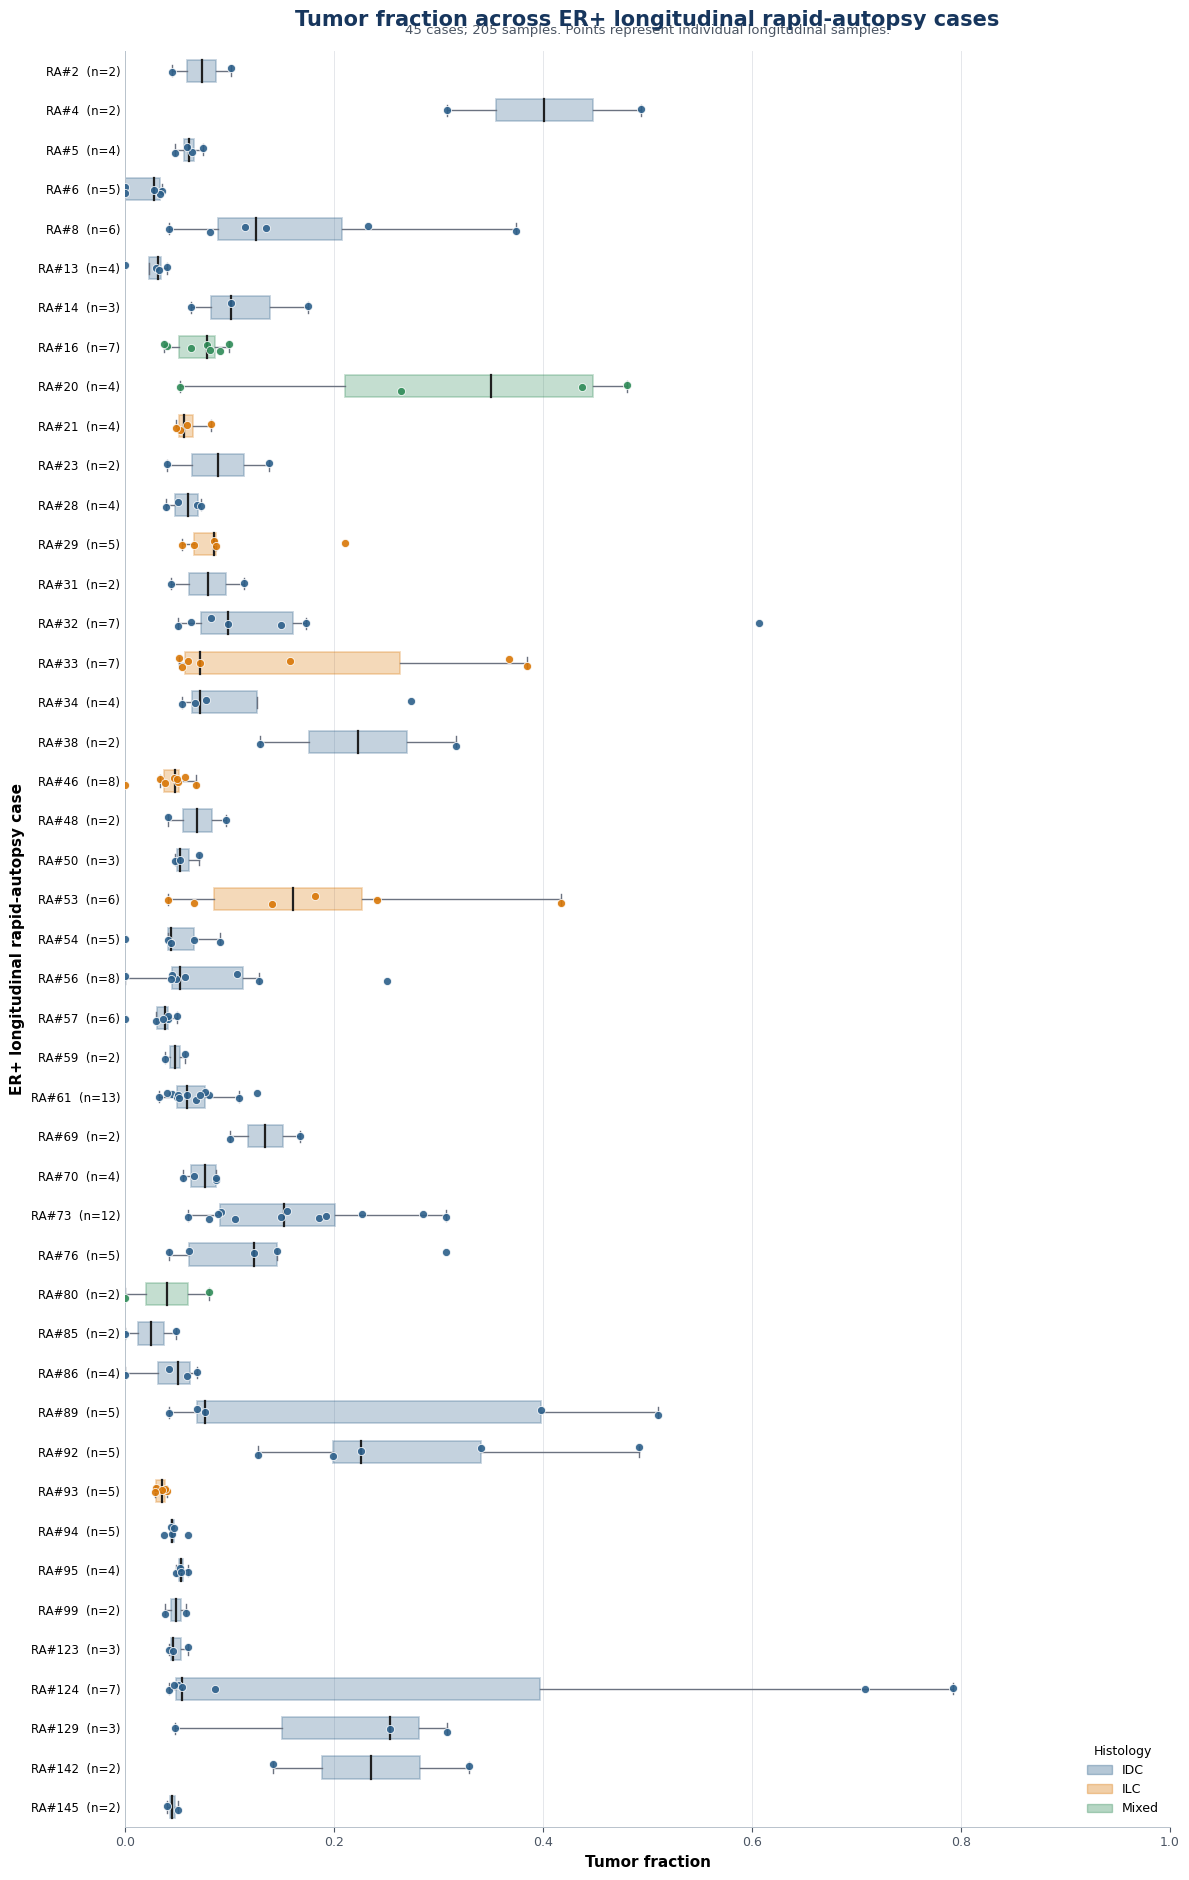


PNG saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/APOLLO/APOLLO_Broad/RA_Cases/RA_ERpos_longitudinal_Tumor_fraction_boxplot.png
PDF saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/APOLLO/APOLLO_Broad/RA_Cases/RA_ERpos_longitudinal_Tumor_fraction_boxplot.pdf


In [2]:
import math
import re
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from openpyxl import load_workbook


# ==============================================================
# Input and output
# ==============================================================

BASE_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/APOLLO/"
    "APOLLO_Broad/RA_Cases"
)

INPUT_XLSX = BASE_DIR / "APOLLO_RA_cfDNA_metrics.xlsx"

OUTPUT_PNG = (
    BASE_DIR /
    "RA_ERpos_longitudinal_Tumor_fraction_boxplot.png"
)

OUTPUT_PDF = (
    BASE_DIR /
    "RA_ERpos_longitudinal_Tumor_fraction_boxplot.pdf"
)


# ==============================================================
# Plot settings
# ==============================================================

HISTOLOGY_COLORS = {
    "IDC": "#2C5F8A",
    "ILC": "#D97706",
    "Mixed": "#2E8B57",
}


def rapid_case_number(case_name):
    """Extract the numeric portion of an RA case label."""
    match = re.search(r"\d+", str(case_name))
    return int(match.group()) if match else 10**9


def histology_group(value):
    """Combine IDC/ILC and ILC/IDC as Mixed."""
    value = str(value or "").strip().upper()

    if value == "IDC":
        return "IDC"

    if value == "ILC":
        return "ILC"

    if value in {"IDC/ILC", "ILC/IDC"}:
        return "Mixed"

    return "Mixed"


def is_er_positive(value):
    """Include positive and weak-positive ER cases."""
    return str(value or "").strip().lower() in {
        "positive",
        "weak positive",
        "pos",
        "weak pos",
    }


def valid_number(value):
    """Convert valid values to float and missing values to NaN."""
    if value is None or str(value).strip() == "":
        return float("nan")

    try:
        value = float(value)

        if math.isnan(value):
            return float("nan")

        return value

    except (TypeError, ValueError):
        return float("nan")


# ==============================================================
# Read workbook
# ==============================================================

if not INPUT_XLSX.is_file():
    raise FileNotFoundError(f"Workbook not found:\n{INPUT_XLSX}")

workbook = load_workbook(
    INPUT_XLSX,
    data_only=True,
    read_only=True,
)

worksheet = workbook["RA cfDNA Metrics"]

headers = [cell.value for cell in worksheet[1]]

column_index = {
    header: index
    for index, header in enumerate(headers)
    if header is not None
}


# ==============================================================
# Reconstruct merged Rapid Cases cells
# ==============================================================

all_cases = defaultdict(list)
current_case = None

for values in worksheet.iter_rows(min_row=2, values_only=True):

    rapid_case_value = values[column_index["Rapid Cases"]]

    if rapid_case_value not in (None, ""):
        current_case = str(rapid_case_value).strip()

    if current_case is None:
        continue

    row = {
        header: values[index]
        for header, index in column_index.items()
    }

    row["Rapid Cases"] = current_case
    all_cases[current_case].append(row)


# ==============================================================
# Select ER+ cases with at least two samples
# ==============================================================

longitudinal_cases = {
    case: rows
    for case, rows in all_cases.items()
    if (
        len(rows) >= 2
        and is_er_positive(rows[0]["ER Status"])
    )
}

ordered_cases = sorted(
    longitudinal_cases,
    key=rapid_case_number,
)

number_of_cases = len(ordered_cases)
number_of_samples = sum(
    len(longitudinal_cases[case])
    for case in ordered_cases
)

print(f"ER+ longitudinal cases: {number_of_cases}")
print(f"Total samples: {number_of_samples}")


# ==============================================================
# Prepare tumor-fraction data
# ==============================================================

plot_data = []
case_labels = []
case_histologies = []
case_colors = []

for case in ordered_cases:

    rows = longitudinal_cases[case]

    tumor_fraction_values = [
        valid_number(row["Tumor_fraction"])
        for row in rows
    ]

    tumor_fraction_values = [
        value
        for value in tumor_fraction_values
        if not math.isnan(value)
    ]

    # Skip a case only if every TF value is missing.
    if not tumor_fraction_values:
        continue

    histology = histology_group(
        rows[0]["Histology  IDC/ILC"]
    )

    plot_data.append(tumor_fraction_values)
    case_labels.append(
        f"{case}  (n={len(tumor_fraction_values)})"
    )
    case_histologies.append(histology)
    case_colors.append(HISTOLOGY_COLORS[histology])


# ==============================================================
# Create horizontal box plot
# ==============================================================

figure_height = max(12, len(plot_data) * 0.42)

figure, axis = plt.subplots(
    figsize=(12, figure_height)
)

positions = np.arange(1, len(plot_data) + 1)

boxplot = axis.boxplot(
    plot_data,
    positions=positions,
    vert=False,
    widths=0.56,
    patch_artist=True,
    showfliers=False,
    whis=1.5,
    medianprops={
        "color": "#1F1F1F",
        "linewidth": 1.6,
    },
    whiskerprops={
        "color": "#6B7280",
        "linewidth": 1.0,
    },
    capprops={
        "color": "#6B7280",
        "linewidth": 1.0,
    },
)

# Apply histology colour to each box.
for box, color in zip(boxplot["boxes"], case_colors):
    box.set_facecolor(color)
    box.set_edgecolor(color)
    box.set_alpha(0.28)
    box.set_linewidth(1.3)


# ==============================================================
# Overlay individual longitudinal samples
# ==============================================================

random_generator = np.random.default_rng(seed=2026)

for position, values, color in zip(
    positions,
    plot_data,
    case_colors,
):

    vertical_jitter = random_generator.uniform(
        -0.12,
        0.12,
        size=len(values),
    )

    axis.scatter(
        values,
        position + vertical_jitter,
        color=color,
        edgecolor="white",
        linewidth=0.6,
        s=34,
        alpha=0.9,
        zorder=3,
    )


# ==============================================================
# Formatting
# ==============================================================

axis.set_yticks(positions)
axis.set_yticklabels(case_labels, fontsize=8.5)

# RA cases appear numerically from top to bottom.
axis.invert_yaxis()

axis.set_xlim(0, 1)

axis.set_xlabel(
    "Tumor fraction",
    fontsize=11,
    fontweight="semibold",
)

axis.set_ylabel(
    "ER+ longitudinal rapid-autopsy case",
    fontsize=11,
    fontweight="semibold",
)

axis.set_title(
    "Tumor fraction across ER+ longitudinal rapid-autopsy cases",
    fontsize=15,
    fontweight="bold",
    color="#17365D",
    pad=18,
)

axis.text(
    0.5,
    1.008,
    (
        f"{number_of_cases} cases; {number_of_samples} samples. "
        "Points represent individual longitudinal samples."
    ),
    transform=axis.transAxes,
    horizontalalignment="center",
    verticalalignment="bottom",
    fontsize=9.5,
    color="#4B5563",
)

axis.grid(
    axis="x",
    color="#E5E7EB",
    linewidth=0.7,
)

axis.set_axisbelow(True)

axis.spines["top"].set_visible(False)
axis.spines["right"].set_visible(False)
axis.spines["left"].set_color("#B8C2CC")
axis.spines["bottom"].set_color("#B8C2CC")

axis.tick_params(
    axis="x",
    labelsize=9,
    colors="#4B5563",
)

axis.tick_params(
    axis="y",
    length=0,
)


# ==============================================================
# Histology legend
# ==============================================================

legend_handles = [
    Patch(
        facecolor=color,
        edgecolor=color,
        alpha=0.35,
        label=histology,
    )
    for histology, color in HISTOLOGY_COLORS.items()
]

axis.legend(
    handles=legend_handles,
    title="Histology",
    loc="lower right",
    frameon=False,
    fontsize=9,
    title_fontsize=9,
)


# ==============================================================
# Save
# ==============================================================

figure.tight_layout()

figure.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

figure.savefig(
    OUTPUT_PDF,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.close(figure)

print(f"\nPNG saved: {OUTPUT_PNG}")
print(f"PDF saved: {OUTPUT_PDF}")